In [17]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.optimize import root
import matplotlib.pyplot as plt

In [18]:
# Physical constants of the TOV Equations and Energy Conversions
 
import math
import numpy as np
# Fundamental constants in SI
G = 6.67430e-11            # gravitational constant [m^3 kg^-1 s^-2]
c = 2.99792458e8           # speed of light [m s^-1]
hbar = 1.054571817e-34     # reduced Planck constant [J s]
M_sun = 1.98847e30         # solar mass [kg]


# Basic unit conversions
eV_to_J = 1.602176634e-19
MeV_to_J = 1.0e6 * eV_to_J

J_to_eV = 1.0 / eV_to_J
J_to_MeV = 1.0 / MeV_to_J

fm_to_m = 1.0e-15
m_to_fm = 1.0 / fm_to_m

km_to_m = 1.0e3
m_to_km = 1.0 / km_to_m



def kg_to_MeV_c2(m_kg):

    return m_kg * c**2 * J_to_MeV


def MeV_c2_to_kg(m_MeV):

    return m_MeV * MeV_to_J / c**2

MeV_fm3_to_J_m3 = MeV_to_J / fm_to_m**3

J_m3_to_MeV_fm3 = 1.0 / MeV_fm3_to_J_m3

def MeV_fm3_to_SI(x):

    return x * MeV_fm3_to_J_m3


def SI_to_MeV_fm3(x):

    return x * J_m3_to_MeV_fm3


In [19]:

# BAG-MODEL PARAMETERS

# P(mu) = a_bag * mu^4 + epsilon0_bag
#
# mu                  : MeV
# P, E                 : MeV/fm^3
# a_bag                : units chosen so a_bag * mu^4
#                        is in MeV/fm^3
# epsilon0_bag         : MeV/fm^3


a_bag = 9.89013e-9
epsilon0_bag = -60.0    # Replace with your value


# ============================================================
# PARAMETER CHECKS
# ============================================================

# For n = dP/dmu = 4 a mu^3 to be positive
# for positive chemical potential, require a > 0

if a_bag <= 0.0:
    print("a must be positive.")
if epsilon0_bag >= 0.0:
    print("To ensure correct boundary conditions at surface, epsilon must be a negative value")


# P = a mu^4 + epsilon0


In [20]:
# ============================================================
# BAG-MODEL EOS

def bag_pressure_mu(mu):

    return (a_bag * mu**4 + epsilon0_bag)


def bag_number_density(mu):
    return (4.0 * a_bag * mu**3)

def bag_energy_mu(mu):

    return (3.0 * a_bag * mu**4 - epsilon0_bag)


def bag_dP_dE(mu=None):
    if mu is None:
        return 1.0 / 3.0

    mu = np.asarray(mu)

    return np.full_like(mu,1.0 / 3.0,dtype=float)


def bag_sound_speed(mu=None):
    return (c * np.sqrt(bag_dP_dE(mu)))

In [21]:
# ============================================================
# BAG EOS IN THE FORM REQUIRED BY TOV
# ============================================================

def bag_mu_from_P(P):
    P = np.maximum(P,0.0)

    P_MeV = SI_to_MeV_fm3(P)
    argument = (P_MeV - epsilon0_bag ) / a_bag

    # mus = (-eps/a)^1/4 the chemical potential


    if np.any(argument < 0.0):
        print("Pressure is outside the physical ""bag-EOS branch.")
        
    mu = (argument**0.25)
    return mu



def bag_e_density(P):


    mu = bag_mu_from_P(P)

    E_MeV = bag_energy_mu(mu)
    # Convert to SI
    E_SI = MeV_fm3_to_SI(E_MeV)
    return E_SI

In [22]:
#

def check_bag_physics(mu_values):

    mu_values = np.asarray(mu_values,dtype=float)

    P = bag_pressure_mu(mu_values)
    E = bag_energy_mu(mu_values)
    n = bag_number_density(mu_values)
    dP_dE = bag_dP_dE(mu_values)
    cs = bag_sound_speed(mu_values)

#physical constraints check
    positive_density = (n > 0.0)
    positive_energy = (E > 0.0)
    stable = (dP_dE > 0.0)
    causal = (dP_dE <= 1.0)

    print("BAG-MODEL PHYSICAL CHECKS")
    print("Minimum dP/dE =",np.min(dP_dE))
    print("Maximum dP/dE =",np.max(dP_dE))
    print("c_s / c =",np.sqrt(dP_dE[0]))
    print()


    if np.all(positive_density):

        print("All good")

    else:print("WARNING: negative density somewhere.")


    if np.all(positive_energy):
        print("All good")

    else:
        print("WARNING: E <= 0 somewhere.")


    if np.all(stable):
        print("All Good")

    else:
        print("WARNING: EOS is mechanically unstable somewhere.")


    if np.all(causal):

        print("all good")
    else:

        print("WARNING:eos not causal.")


    physical = (positive_density & positive_energy & stable & causal)


    if np.all(physical):
        print()
        print("Bag EOS passes all tested physical conditions.")


    return (P,E,n,dP_dE,cs)

In [23]:
#surface boundary condition

mu_surface = (-epsilon0_bag/ a_bag)**0.25


E_surface_MeV = bag_energy_mu(mu_surface)


print("Surface chemical potential =",mu_surface,"MeV")
print("Surface pressure =",bag_pressure_mu(mu_surface),"MeV/fm^3")
print("Surface energy density =",E_surface_MeV,"MeV/fm^3")

Surface chemical potential = 279.08552533255903 MeV
Surface pressure = 0.0 MeV/fm^3
Surface energy density = 240.0 MeV/fm^3


In [24]:
# ============================================================
# CHEMICAL-POTENTIAL RANGE FOR EOS TEST
# ============================================================
c =  2.99792458e8
mu_check = np.linspace(1.0 * mu_surface,2.5 * mu_surface,1000)


(P_check_bag,E_check_bag,n_check_bag,dP_dE_bag,cs_bag) = check_bag_physics(mu_check)

BAG-MODEL PHYSICAL CHECKS
Minimum dP/dE = 0.3333333333333333
Maximum dP/dE = 0.3333333333333333
c_s / c = 0.5773502691896257

All good
All good
All Good
all good

Bag EOS passes all tested physical conditions.


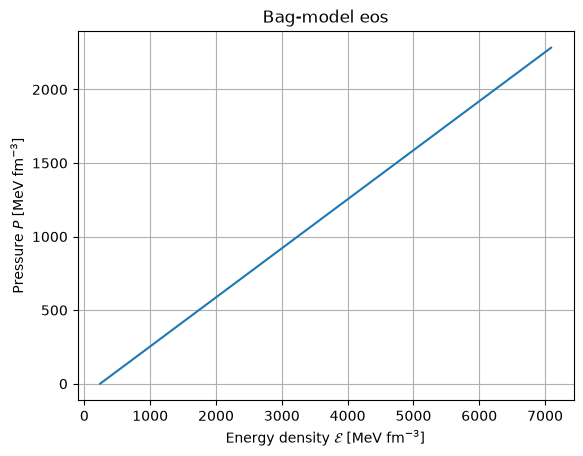

In [25]:
#eos plot
plt.plot(E_check_bag,P_check_bag)
plt.xlabel(r"Energy density $\mathcal{E}$ [MeV fm$^{-3}$]")
plt.ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
plt.title("Bag-model eos")
plt.grid()
plt.show()

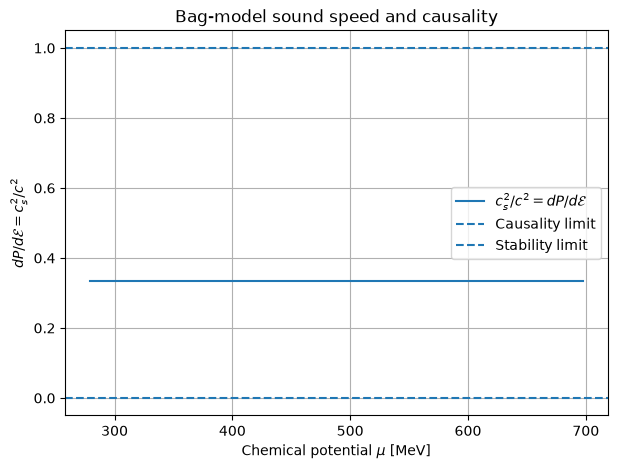

In [26]:
# ============================================================
# BAG MODEL SOUND SPEED / CAUSALITY
# ============================================================

plt.figure(figsize=(7, 5))


plt.plot(mu_check,dP_dE_bag,label=r"$c_s^2/c^2=dP/d\mathcal{E}$")
plt.axhline(1.0,linestyle="--",label="Causality limit")
plt.axhline(0.0,linestyle="--",label="Stability limit")
plt.xlabel(r"Chemical potential $\mu$ [MeV]")
plt.ylabel(r"$dP/d\mathcal{E}=c_s^2/c^2$")
plt.title("Bag-model sound speed and causality")
plt.grid()
plt.legend()
plt.show()

In [27]:
# ============================================================
# TOV EQUATIONS USING PHYSICALLY CHECKED BAG EOS
# ============================================================

def tov_equations_bag(r, y):

    m, P = y
        
    if P <= 0.0:

        return [0.0,0.0]

    E = bag_e_density(P)

    dP_dE = bag_dP_dE()
    if dP_dE <= 0.0:
        raise RuntimeError("Bag EOS violates stability: dP/dE <= 0.")


    if dP_dE > 1.0:
        raise RuntimeError("Bag EOS violates causality: dP/dE > 1.")


    if E <= 0.0:
        raise RuntimeError("Bag EOS produced E <= 0.")

    dmdr = 4.0 * np.pi * r**2 * E/ c**2
    t1 = G * E * m / (c**2 * r**2)

    t2 = 1.0 + P / E

    t3 = 1.0 + (4.0 * np.pi * r**3 * P) / (m * c**2)

    t4 = 1.0 - (2.0 * G * m) / (c**2 * r)

    dPdr = -t1 * t2 * t3 / t4
    return [dmdr, dPdr]


    

In [28]:

def bag_surface_event(r, y):
    m, P = y
    return P
bag_surface_event.terminal = True
bag_surface_event.direction = -1

In [29]:

def solve_star_bag(mu_c,r_start=1.0e-3,r_max=5.0e4,rtol=1.0e-7,atol=(1.0e-6, 1.0e18),max_step=25.0):


    P_c_MeV = bag_pressure_mu(mu_c)

    if P_c_MeV <= 0.0:
        raise ValueError("Central chemical potential gives P_c <= 0.")

    P_c = MeV_fm3_to_SI(P_c_MeV)


    E_c = bag_e_density(P_c)

    m_start = ((4.0 * np.pi / 3.0)* r_start**3* E_c/ c**2)

    P_start = P_c
    y_start = [m_start,P_start]

    solution = solve_ivp(tov_equations_bag,t_span=(r_start,r_max),y0=y_start,events=bag_surface_event,rtol=rtol,atol=atol,max_step=max_step)

    if solution.t_events[0].size == 0:

        raise RuntimeError("Bag-star integration did not reach P = 0.")


    R = (solution.t_events[0][0])

    M = (solution.y_events[0][0][0])

    E_surface = bag_e_density(0.0)


    return (solution,R,M,P_c,E_c,E_surface)

In [30]:

if epsilon0_bag >= 0.0:

    raise ValueError("For P = a mu^4 + epsilon0, ""epsilon0 must be negative for a pure " "self-bound star with P = 0.")
mu_surface = (-epsilon0_bag / a_bag)**0.25
print("Surface chemical potential =",mu_surface,"MeV")
print("Surface energy density =",SI_to_MeV_fm3(bag_e_density(0.0)),"MeV/fm^3")

Surface chemical potential = 279.08552533255903 MeV
Surface energy density = 240.0 MeV/fm^3


In [31]:
#sequence generator

mu_c_values = np.linspace(1.01 * mu_surface,2.5 * mu_surface,150)


bag_masses = []
bag_radii = []
successful_mu_c = []


for mu_c_trial in mu_c_values:

    try:

        (
            solution_trial,
            R_trial,
            M_trial,
            P_c_trial,
            E_c_trial,
            E_surface_trial

        ) = solve_star_bag(
            mu_c_trial
        )


        bag_radii.append(
            R_trial / 1000.0
        )

        bag_masses.append(
            M_trial / M_sun
        )

        successful_mu_c.append(
            mu_c_trial
        )


    except RuntimeError:
        continue


bag_radii = np.array(bag_radii)
bag_masses = np.array(bag_masses)
successful_mu_c = np.array(successful_mu_c)

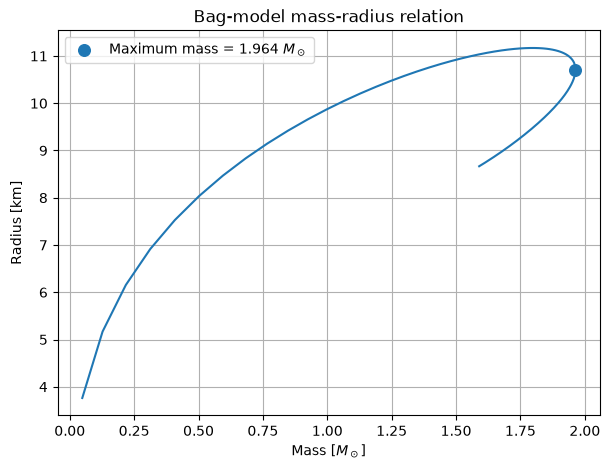

Maximum mass = 1.9636158637687857 M_sun
Radius at maximum mass = 10.711594584484684 km
Central chemical potential = 438.16427477211766 MeV


In [37]:

plt.plot(bag_masses,bag_radii)

i_bag_max = np.argmax(bag_masses)
bag_M_max = (bag_masses[i_bag_max])
bag_R_at_Mmax = (bag_radii[i_bag_max])

bag_mu_at_Mmax = (successful_mu_c[i_bag_max])


plt.scatter(bag_M_max,bag_R_at_Mmax,s=70,label=(f"Maximum mass = "f"{bag_M_max:.3f} $M_\\odot$"))


plt.xlabel(r"Mass [$M_\odot$]")
plt.ylabel("Radius [km]")
plt.title("Bag-model mass-radius relation")
plt.grid()
plt.legend()
plt.show()

print("Maximum mass =",bag_M_max,"M_sun")
print("Radius at maximum mass =",bag_R_at_Mmax,"km")
print("Central chemical potential =",bag_mu_at_Mmax,"MeV")

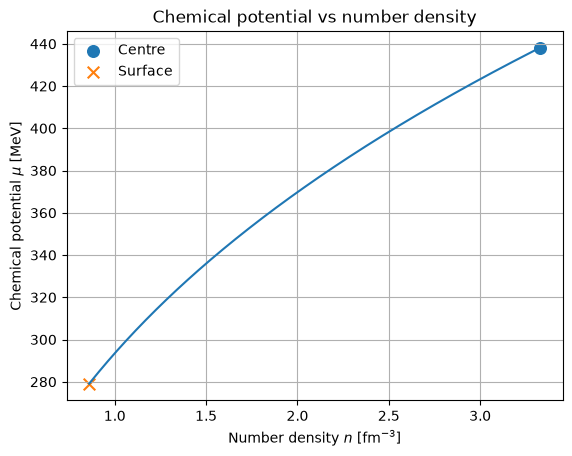

In [39]:
(solution_bag,R_bag,M_bag,P_c_bag,E_c_bag,E_surface_bag) = solve_star_bag(bag_mu_at_Mmax)
r_profile_bag = solution_bag.t
P_profile_bag = solution_bag.y[1]
P_profile_bag = np.maximum(P_profile_bag,0.0)
mu_profile_bag = bag_mu_from_P(P_profile_bag)
n_profile_bag = bag_number_density(mu_profile_bag)
sort_index = np.argsort(n_profile_bag)
n_plot = n_profile_bag[sort_index]
mu_plot = mu_profile_bag[sort_index]
plt.plot(n_plot,mu_plot)


plt.scatter(n_profile_bag[0],mu_profile_bag[0],s=70,label="Centre")
plt.scatter(n_profile_bag[-1],mu_profile_bag[-1],s=70,marker="x",label="Surface")


plt.xlabel(r"Number density $n$ [fm$^{-3}$]")
plt.ylabel(r"Chemical potential $\mu$ [MeV]")
plt.title("Chemical potential vs number density")
plt.grid()
plt.legend()

plt.show()